## Step 1 : EDA
+ #### Exploratory Data Analysis

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df = pd.read_csv("credit_risk.csv")
df.head()

,Id,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
0,0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


In [63]:
df.shape

(32581, 12)

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              32581 non-null  int64  
 1   Age             32581 non-null  int64  
 2   Income          32581 non-null  int64  
 3   Home            32581 non-null  str    
 4   Emp_length      31686 non-null  float64
 5   Intent          32581 non-null  str    
 6   Amount          32581 non-null  int64  
 7   Rate            29465 non-null  float64
 8   Status          32581 non-null  int64  
 9   Percent_income  32581 non-null  float64
 10  Default         32581 non-null  str    
 11  Cred_length     32581 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 3.0 MB


In [65]:
df.describe()

,Id,Age,Income,Emp_length,Amount,Rate,Status,Percent_income,Cred_length
count,32581.000000,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,16290.006139,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,9405.479594,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,0.000000,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,8145.000000,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,16290.000000,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,24435.000000,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,32780.000000,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [66]:
df.isnull().sum()

Id                   0
Age                  0
Income               0
Home                 0
Emp_length         895
Intent               0
Amount               0
Rate              3116
Status               0
Percent_income       0
Default              0
Cred_length          0
dtype: int64

In [67]:
df.nunique()

Id                32581
Age                  58
Income             4295
Home                  4
Emp_length           36
Intent                6
Amount              753
Rate                348
Status                2
Percent_income       77
Default               2
Cred_length          29
dtype: int64

In [68]:
df.sort_values(by="Age", ascending=False).head(10)

,Id,Age,Income,Home,Emp_length,Intent,Amount,Rate,Status,Percent_income,Default,Cred_length
81,81,144,250000,RENT,4.0,VENTURE,4800,13.57,0,0.02,N,3
183,183,144,200000,MORTGAGE,4.0,EDUCATION,6000,11.86,0,0.03,N,2
32297,32297,144,6000000,MORTGAGE,12.0,PERSONAL,5000,12.73,0,0.00,N,25
575,575,123,80004,RENT,2.0,EDUCATION,20400,10.25,0,0.25,N,3
747,747,123,78000,RENT,7.0,VENTURE,20000,NaN,0,0.26,N,4
32416,32416,94,24000,RENT,1.0,MEDICAL,6500,NaN,0,0.27,N,27
32506,32506,84,94800,MORTGAGE,2.0,PERSONAL,10000,7.51,0,0.11,N,24
32422,32422,80,64000,RENT,7.0,MEDICAL,6800,11.71,0,0.11,N,25
32355,32355,78,48000,RENT,41.0,MEDICAL,3000,7.51,0,0.06,N,25
32534,32534,76,75000,RENT,23.0,MEDICAL,15000,8.94,0,0.20,N,25


In [74]:
correlation = df.corr(numeric_only=True)
correlation

,Id,Age,Income,Emp_length,Amount,Rate,Status,Percent_income,Cred_length
Id,1.000000,0.734248,0.170488,0.186934,0.100978,0.001918,-0.060256,-0.069398,0.772918
Age,0.734248,1.000000,0.173202,0.163106,0.050787,0.012580,-0.021629,-0.042411,0.859133
Income,0.170488,0.173202,1.000000,0.134268,0.266820,0.000792,-0.144449,-0.254471,0.117987
Emp_length,0.186934,0.163106,0.134268,1.000000,0.113082,-0.056405,-0.082489,-0.054111,0.144699
Amount,0.100978,0.050787,0.266820,0.113082,1.000000,0.146813,0.105376,0.572612,0.041967
Rate,0.001918,0.012580,0.000792,-0.056405,0.146813,1.000000,0.335133,0.120314,0.016696
Status,-0.060256,-0.021629,-0.144449,-0.082489,0.105376,0.335133,1.000000,0.379366,-0.015529
Percent_income,-0.069398,-0.042411,-0.254471,-0.054111,0.572612,0.120314,0.379366,1.000000,-0.031690
Cred_length,0.772918,0.859133,0.117987,0.144699,0.041967,0.016696,-0.015529,-0.031690,1.000000


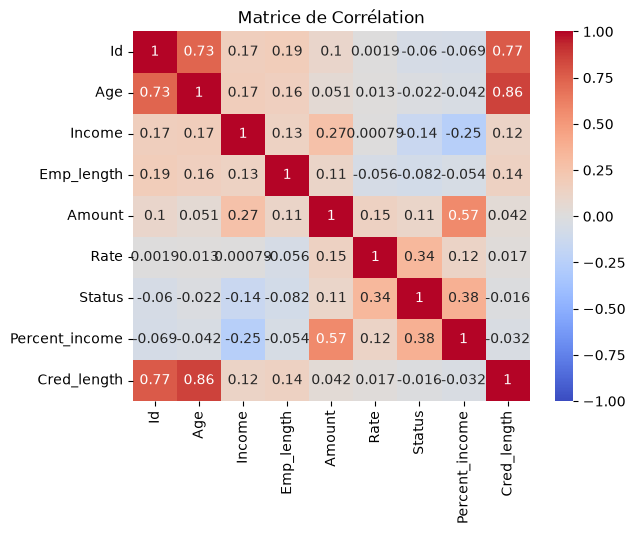

In [87]:
sns.heatmap(correlation, annot=True,  cmap="coolwarm", vmax= 1, vmin= -1)
plt.title("Matrice de Corrélation") 
plt.show()